# Reconnaître la race d'un chien sur une photo, sans deep learning

Projet du cours d'introduction au Machine Learning (Polytech Nice Sophia). Le but : distinguer
**6 races de chiens** à partir de photos, avec des outils classiques (PCA, HOG, k-NN, SVM) et
scikit-learn. Toutes les races ont la même structure (quatre pattes, deux oreilles, une truffe) et
les photos sont prises dans des conditions très variées, donc la préparation des images compte
autant que le choix du modèle.

Les images viennent de la base **SmallDB** fournie avec le cours (un extrait du *Stanford Dogs
Dataset*). La cellule suivante la télécharge si elle n'est pas déjà là.

In [1]:
import os
import shutil
import subprocess
import time
import xml.etree.ElementTree as ET

import numpy as np
import matplotlib.pyplot as plt
import skimage.io as io
from skimage.transform import resize
from skimage.filters import sobel, sobel_h, sobel_v
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, hamming_loss
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

if not os.path.exists("SmallDB"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pns-mam/ml-intro.git"], check=True)
    shutil.move(os.path.join("ml-intro", "SmallDB"), "SmallDB")
    shutil.rmtree("ml-intro")
print("SmallDB :", sorted(os.listdir(os.path.join("SmallDB", "Images"))))

TARGET_SIZE = (64, 64)
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

SmallDB : ['n02085620-Chihuahua', 'n02088238-basset', 'n02093859-Kerry_blue_terrier', 'n02105056-groenendael', 'n02105162-malinois', 'n02112137-chow']


## 1. Charger les images et les recadrer sur le chien

Chaque photo a un fichier XML qui donne la boîte englobante du chien (`xmin`, `ymin`, `xmax`, `ymax`).
On s'en sert pour couper l'image autour du chien : sinon le modèle risque d'apprendre que « herbe
verte = basset » au lieu de regarder l'animal. Les images sont lues en niveaux de gris.

1002 images, 6 races


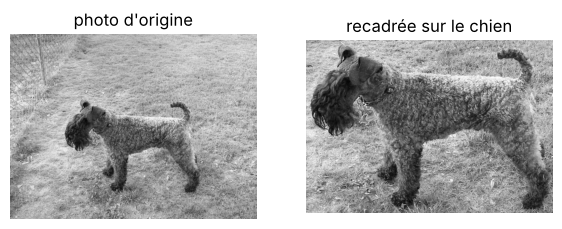

In [2]:
def boite_englobante(fichier_xml):
    box = ET.parse(fichier_xml).getroot().find("object/bndbox")
    return [int(box.find(k).text) for k in ("xmin", "xmax", "ymin", "ymax")]


def charger_base(dossier="SmallDB"):
    images, chiens, labels, noms = [], [], [], {}
    races = sorted(d for d in os.listdir(os.path.join(dossier, "Images")) if "-" in d)
    for k, race in enumerate(races):
        noms[k] = race.split("-", 1)[1]
        for f in sorted(os.listdir(os.path.join(dossier, "Images", race))):
            img = io.imread(os.path.join(dossier, "Images", race, f), as_gray=True)
            xmin, xmax, ymin, ymax = boite_englobante(os.path.join(dossier, "Annotation", race, os.path.splitext(f)[0]))
            images.append(img)
            chiens.append(img[ymin:ymax + 1, xmin:xmax + 1])
            labels.append(k)
    return images, chiens, np.array(labels), noms


images, chiens, labels, noms = charger_base()
print(len(labels), "images,", len(noms), "races")

fig, (a0, a1) = plt.subplots(1, 2, figsize=(7, 3.5))
a0.imshow(images[328], cmap="gray"); a0.set_title("photo d'origine"); a0.axis("off")
a1.imshow(chiens[328], cmap="gray"); a1.set_title("recadrée sur le chien"); a1.axis("off")
plt.show()

### Les classes sont-elles équilibrées ?

On le mesure avec l'entropie de Shannon $H(p) = -\sum_k p_k \ln p_k$, où $p_k$ est la proportion
d'images de la race $k$. Elle vaut au maximum $\ln(K)$, quand toutes les races ont autant d'images.

In [3]:
def entropie(effectifs):
    p = np.asarray(effectifs, float) / np.sum(effectifs)
    p = p[p > 0]
    return -np.sum(p * np.log(p))


effectifs = np.bincount(labels)
for k, n in enumerate(effectifs):
    print(f"{noms[k]:20s} {n}")
print(f"\nH = {entropie(effectifs):.4f}   (maximum ln(6) = {np.log(6):.4f})")

Chihuahua            152
basset               175
Kerry_blue_terrier   179
groenendael          150
malinois             150
chow                 196

H = 1.7863   (maximum ln(6) = 1.7918)


$H = 1{,}7863$ contre $1{,}7918$ au maximum : la base est bien équilibrée, aucune race ne domine.

## 2. Redimensionner sans déformer

Tous les modèles ont besoin d'images de même taille (64 × 64). Étirer une photo rectangulaire pour
la rendre carrée déforme le chien, et ce sont justement les proportions (museau, corps, oreilles) qui
distinguent les races. On réduit donc l'image en gardant ses proportions et on complète avec un fond
uni (*letterboxing*). Trois remplissages sont possibles : blanc, noir, ou en prolongeant les pixels du bord.

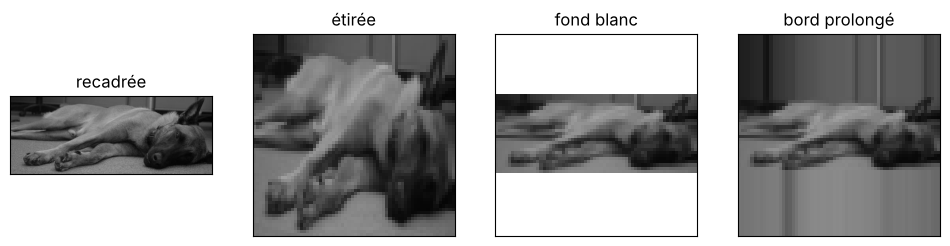

train : (751, 4096)  test : (251, 4096)


In [4]:
def resize_and_pad(img, taille=TARGET_SIZE, pad="white"):
    h, w = img.shape[:2]
    H, W = taille
    r = min(H / h, W / w)
    nh, nw = max(1, round(h * r)), max(1, round(w * r))
    haut, gauche = (H - nh) // 2, (W - nw) // 2
    petit = resize(img, (nh, nw), anti_aliasing=True)
    if pad == "continuous":
        return np.pad(petit, [(haut, H - nh - haut), (gauche, W - nw - gauche)], mode="edge")
    out = np.full((H, W), 1.0 if pad == "white" else 0.0)
    out[haut:haut + nh, gauche:gauche + nw] = petit
    return out


exemple = chiens[int(np.argmax([c.shape[1] / c.shape[0] for c in chiens]))]   # le chien le plus allongé
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (im, t) in zip(axes, [(exemple, "recadrée"), (resize(exemple, TARGET_SIZE), "étirée"),
                              (resize_and_pad(exemple), "fond blanc"), (resize_and_pad(exemple, pad="continuous"), "bord prolongé")]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
plt.show()

X_all = np.array([resize_and_pad(c).ravel() for c in chiens])      # une image = une ligne de 4096 pixels
X_train, X_test, y_train, y_test = train_test_split(X_all, labels, test_size=0.25, stratify=labels,
                                                    random_state=RANDOM_STATE)
print("train :", X_train.shape, " test :", X_test.shape)

La séparation train / test (75 / 25 %) est **stratifiée** : chaque race garde la même proportion des
deux côtés. Pour le vérifier, on calcule la similarité cosinus entre les deux distributions de classes
(1 = identiques).

In [5]:
p_train = np.bincount(y_train) / len(y_train)
p_test = np.bincount(y_test) / len(y_test)
print(f"similarité cosinus train / test : {p_train @ p_test / (np.linalg.norm(p_train) * np.linalg.norm(p_test)):.6f}")

similarité cosinus train / test : 0.999951


## 3. La PCA : compresser les images

Un pixel mesure de la lumière, pas une forme : donner 4 096 pixels bruts au modèle marche mal. La PCA
cherche les directions dans lesquelles les images varient le plus. scikit-learn passe par la SVD de la
matrice centrée, ce qui évite de construire une matrice de covariance 4 096 × 4 096.

Important : la PCA est apprise sur le **train uniquement**.

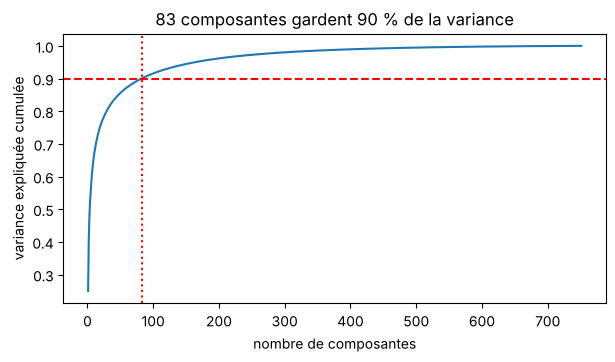

In [6]:
def my_PCA(data, n_components=None):
    return PCA(n_components=n_components, svd_solver="full").fit(data)


pca = my_PCA(X_train)
cum = np.cumsum(pca.explained_variance_ratio_)
k90 = int(np.searchsorted(cum, 0.90) + 1)

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, len(cum) + 1), cum)
plt.axhline(0.9, color="red", ls="--")
plt.axvline(k90, color="red", ls=":")
plt.xlabel("nombre de composantes"); plt.ylabel("variance expliquée cumulée")
plt.title(f"{k90} composantes gardent 90 % de la variance")
plt.show()

Pour s'en convaincre, on reconstruit une image avec seulement $k$ composantes :
image $\approx$ moyenne $+ w_1\,vp_1 + \dots + w_k\,vp_k$.

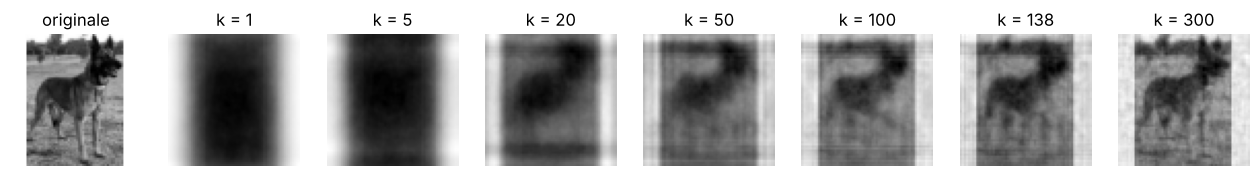

In [7]:
img = X_train[0]
coords = pca.transform(img[None, :])[0]
ks = [1, 5, 20, 50, 100, 138, 300]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(16, 2.6))
axes[0].imshow(img.reshape(TARGET_SIZE), cmap="gray"); axes[0].set_title("originale")
for ax, k in zip(axes[1:], ks):
    approx = pca.mean_ + coords[:k] @ pca.components_[:k]
    ax.imshow(approx.reshape(TARGET_SIZE), cmap="gray"); ax.set_title(f"k = {k}")
for ax in axes:
    ax.axis("off")
plt.savefig("figures/pca_reconstruction.png", dpi=150, bbox_inches="tight")
plt.show()

Vers $k \approx 140$ le chien est déjà bien reconnaissable avec 30 fois moins de nombres.
Mais quand on place toutes les images sur les deux premiers axes, les races sont complètement
mélangées : la PCA globale résume bien les images, sans pour autant séparer les races.

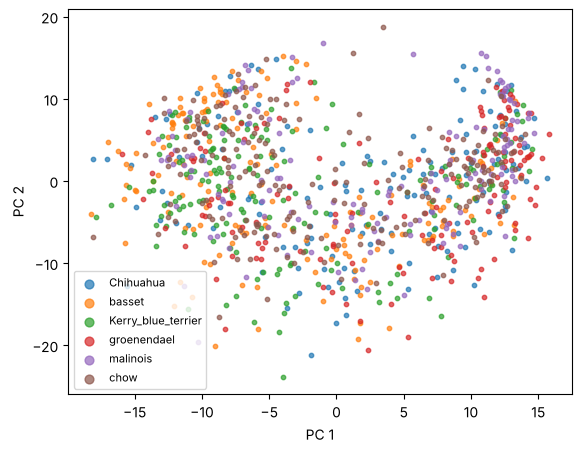

In [8]:
proj = pca.transform(X_all)[:, :2]
plt.figure(figsize=(6.5, 5))
for k, nom in noms.items():
    plt.scatter(proj[labels == k, 0], proj[labels == k, 1], s=10, alpha=0.7, label=nom)
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.legend(markerscale=2, fontsize=8)
plt.show()

### Une PCA par race

Idée : apprendre une PCA **par race** (5 axes chacune), puis projeter chaque image sur les axes des
6 races. Une image de chow est bien décrite par les axes appris sur les chows, moins bien par les
autres. On obtient un vecteur de $6 \times 5 = 30$ valeurs qui dit en quelque sorte « à quelle race
l'image ressemble ».

## 4. Le HOG : la forme des contours

Le HOG (*histogram of oriented gradients*) décrit la silhouette. Les filtres de Sobel mesurent les
variations de luminosité dans les deux directions : le décor plat devient noir, les contours
ressortent. On découpe ensuite l'image en cellules et, dans chacune, on fait l'histogramme des
directions des contours, pondéré par leur intensité. Avec 4 × 4 cellules et 8 directions : 128 valeurs.

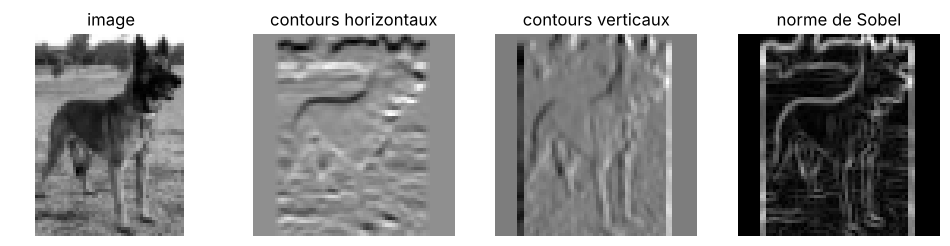

In [9]:
im = X_train[0].reshape(TARGET_SIZE)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (a, t) in zip(axes, [(im, "image"), (sobel_h(im), "contours horizontaux"),
                             (sobel_v(im), "contours verticaux"), (sobel(im), "norme de Sobel")]):
    ax.imshow(a, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()


def compute_hog(image, nb_h=4, nb_w=4, nb_bins=8):
    h_edge, v_edge = sobel_h(image), sobel_v(image)
    norme = np.sqrt(h_edge ** 2 + v_edge ** 2)
    angle = np.arctan2(v_edge, h_edge)
    angle[angle < 0] += np.pi                        # directions dans [0, pi)
    ch, cw = image.shape[0] // nb_h, image.shape[1] // nb_w
    hist = np.zeros((nb_h, nb_w, nb_bins))
    for i in range(nb_h):
        for j in range(nb_w):
            cellule = (slice(i * ch, (i + 1) * ch), slice(j * cw, (j + 1) * cw))
            bins = np.minimum((angle[cellule] // (np.pi / nb_bins)).astype(int), nb_bins - 1)
            hist[i, j] = np.bincount(bins.ravel(), weights=norme[cellule].ravel(), minlength=nb_bins)
    return hist.ravel()

## 5. Premier modèle : les k plus proches voisins

Le k-NN regarde les $k$ images d'entraînement les plus proches et prend la race majoritaire.
On lui donne les 30 valeurs de la PCA par race et les 128 du HOG, standardisées.

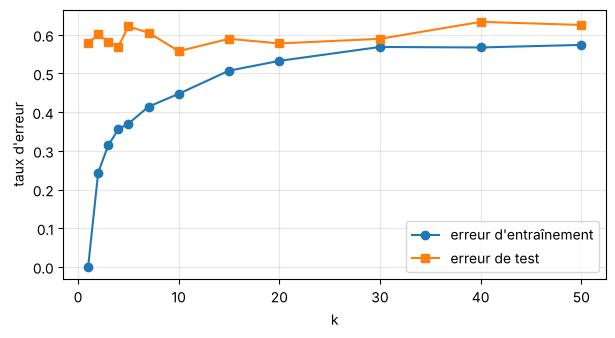

meilleur k = 10, erreur de test = 55.8%


In [10]:
pcas_par_race = [my_PCA(X_train[y_train == k], 5) for k in sorted(noms)]


def caracteristiques(X):
    pca_feat = np.hstack([p.transform(X) for p in pcas_par_race])
    hog_feat = np.array([compute_hog(x.reshape(TARGET_SIZE)) for x in X])
    return np.hstack([pca_feat, hog_feat])


scaler = StandardScaler().fit(caracteristiques(X_train))
F_train, F_test = scaler.transform(caracteristiques(X_train)), scaler.transform(caracteristiques(X_test))

ks = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50]
err_train, err_test = [], []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(F_train, y_train)
    err_train.append(hamming_loss(y_train, knn.predict(F_train)))
    err_test.append(hamming_loss(y_test, knn.predict(F_test)))

plt.figure(figsize=(7, 3.5))
plt.plot(ks, err_train, "o-", label="erreur d'entraînement")
plt.plot(ks, err_test, "s-", label="erreur de test")
plt.xlabel("k"); plt.ylabel("taux d'erreur"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
print(f"meilleur k = {ks[int(np.argmin(err_test))]}, erreur de test = {min(err_test):.1%}")

Avec $k = 1$ l'erreur d'entraînement est nulle (chaque image est sa propre voisine) mais l'erreur de
test reste autour de 55-60 % quel que soit $k$. Le modèle apprend les images par cœur au lieu de
comprendre la forme des races : c'est du **surapprentissage**. On passe à un SVM.

## 6. Le SVM dans un Pipeline

Un SVM cherche la frontière qui sépare les classes avec la plus grande marge. Avec le noyau RBF, la
frontière peut être courbe. Deux réglages : $C$ (la sévérité envers les erreurs d'entraînement) et
$\gamma$ (le rayon d'influence de chaque point).

Avant ça, un point important : la **fuite de données**. Si on calcule la PCA ou la standardisation
sur toutes les images avant de séparer train et test, une partie de l'information du test passe dans
l'entraînement et le score devient trop optimiste. Le problème est encore plus sournois avec la
validation croisée, où il faudrait tout recalculer dans chaque pli.

La solution propre : transformer nos extracteurs en **briques scikit-learn** (classes qui héritent de
`BaseEstimator` et `TransformerMixin`) et tout ranger dans un `Pipeline`. scikit-learn se charge
alors de n'apprendre chaque étape que sur les données d'entraînement, partout.

In [11]:
class EdgeInfoPreprocessing(BaseEstimator, TransformerMixin):
    """HOG : rien à apprendre."""
    def __init__(self, nb_h_cells=4, nb_w_cells=4, nb_bins=8):
        self.nb_h_cells, self.nb_w_cells, self.nb_bins = nb_h_cells, nb_w_cells, nb_bins

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.array([compute_hog(x.reshape(TARGET_SIZE), self.nb_h_cells, self.nb_w_cells, self.nb_bins) for x in X])


class PCAInfoPreprocessing(BaseEstimator, TransformerMixin):
    """Une PCA par race, apprise sur le train ; transform projette sur les axes de toutes les races."""
    def __init__(self, n_components=5):
        self.n_components = n_components

    def fit(self, X, y=None):
        self.pca_per_class_ = [my_PCA(X[y == c], self.n_components) for c in np.unique(y)]
        return self

    def transform(self, X):
        return np.hstack([p.transform(X) for p in self.pca_per_class_])


def pipeline(classifieur, n_pca=5, hog_cells=(4, 4), hog_bins=8):
    return Pipeline([
        ("minmax_scaler", MinMaxScaler()),
        ("feature_union", FeatureUnion([
            ("pca_features", PCAInfoPreprocessing(n_pca)),
            ("hog_features", EdgeInfoPreprocessing(hog_cells[0], hog_cells[1], hog_bins)),
        ])),
        ("standard_scaler", StandardScaler()),     # sinon le HOG (128 grandes valeurs) écrase la PCA
        ("classifier", classifieur),
    ])

## 7. Régler $C$, $\gamma$ et le nombre de composantes

`GridSearchCV` essaie toutes les combinaisons avec une validation croisée à 3 plis : le train est
coupé en 3, on apprend sur 2 morceaux et on évalue sur le 3e, trois fois. Le test n'intervient jamais
dans le choix. Les noms de paramètres suivent le chemin dans le Pipeline (`étape__paramètre`).

In [12]:
grille = GridSearchCV(
    pipeline(SVC(kernel="rbf")),
    {"feature_union__pca_features__n_components": [5, 10, 20],
     "classifier__C": [0.1, 1, 10],
     "classifier__gamma": [0.01, 0.05, 0.1, 0.25, 0.5]},
    cv=3, n_jobs=-1)
grille.fit(X_train, y_train)
print("meilleurs paramètres :", grille.best_params_)
print(f"score moyen en validation croisée : {grille.best_score_:.2%}")
print(f"score sur le test : {grille.score(X_test, y_test):.2%}")

meilleurs paramètres : {'classifier__C': 10, 'classifier__gamma': 0.01, 'feature_union__pca_features__n_components': 5}
score moyen en validation croisée : 56.98%
score sur le test : 59.36%


Environ 59 % sur 6 races, contre 16,7 % au hasard. Une recherche plus large, qui règle aussi la PCA
et le HOG, prend plusieurs heures : elle n'est pas relancée dans ce notebook. Elle avait retenu un
SVM avec $C = 1000$, `gamma="scale"`, `class_weight="balanced"`, 20 composantes par race, et un HOG
de 8 × 4 cellules avec 9 directions.

## 8. One-vs-One ou One-vs-Rest ?

Un SVM ne sépare que deux classes. Pour 6 races il faut en combiner plusieurs :

- **One-vs-One** : un SVM par duel de races, soit $6 \times 5 / 2 = 15$ SVM, puis un vote ;
- **One-vs-Rest** : un SVM par race contre toutes les autres, soit 6 SVM ; le plus confiant gagne.

In [13]:
def meilleur_pipeline(strategie):
    svm = SVC(kernel="rbf", C=1000, gamma="scale", class_weight="balanced")
    return pipeline(strategie(svm), n_pca=20, hog_cells=(8, 4), hog_bins=9)


def evaluer(strategie, Xtr, ytr, Xte, yte):
    p = meilleur_pipeline(strategie)
    t0 = time.time()
    p.fit(Xtr, ytr)
    y_pred = p.predict(Xte)
    return np.mean(y_pred == yte), y_pred, len(p.named_steps["classifier"].estimators_), time.time() - t0


resultats = {}
for nom, strat in [("OvO", OneVsOneClassifier), ("OvR", OneVsRestClassifier)]:
    resultats[nom] = evaluer(strat, X_train, y_train, X_test, y_test)
    score, _, n_svm, duree = resultats[nom]
    print(f"{nom} : {score:.2%} de bonnes réponses, {n_svm} SVM, {duree:.1f} s")

OvO : 61.35% de bonnes réponses, 15 SVM, 1.6 s
OvR : 60.56% de bonnes réponses, 6 SVM, 1.8 s


Les deux stratégies font jeu égal (autour de 60 %). One-vs-Rest a besoin de 2,5 fois moins de modèles,
c'est donc le choix le plus raisonnable.

## 9. L'augmentation de données et le piège de la fuite

Pour dépasser ces 60 %, on a essayé de doubler la base en ajoutant le **miroir** de chaque image.
Première tentative : ajouter les miroirs à toute la base, puis séparer train et test.

In [14]:
def miroir(X):
    return X.reshape(-1, *TARGET_SIZE)[:, :, ::-1].reshape(len(X), -1)


# Mauvaise méthode : on double la base PUIS on sépare
X_aug = np.vstack([X_all, miroir(X_all)])
y_aug = np.concatenate([labels, labels])
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_aug, y_aug, test_size=0.25, stratify=y_aug, random_state=RANDOM_STATE)
for nom, strat in [("OvO", OneVsOneClassifier), ("OvR", OneVsRestClassifier)]:
    print(f"miroirs avant le split, {nom} : {evaluer(strat, Xa_tr, ya_tr, Xa_te, ya_te)[0]:.2%}")

miroirs avant le split, OvO : 66.47%
miroirs avant le split, OvR : 65.87%


Le score grimpe à environ 66 %... mais c'est de la triche. Une photo peut se retrouver dans le train et **son
miroir dans le test**. Comme le HOG et la PCA donnent des caractéristiques très proches pour une image
et son miroir, le modèle reconnaît des chiens qu'il a déjà vus.

La bonne méthode : séparer d'abord, puis n'ajouter les miroirs **que dans le train**. Le test reste
composé de photos jamais vues.

In [15]:
Xb_tr = np.vstack([X_train, miroir(X_train)])
yb_tr = np.concatenate([y_train, y_train])
for nom, strat in [("OvO", OneVsOneClassifier), ("OvR", OneVsRestClassifier)]:
    resultats[nom + " + miroirs"] = evaluer(strat, Xb_tr, yb_tr, X_test, y_test)
    print(f"miroirs dans le train seulement, {nom} : {resultats[nom + ' + miroirs'][0]:.2%}")

miroirs dans le train seulement, OvO : 61.35%
miroirs dans le train seulement, OvR : 62.55%


Le gain réel existe (environ +2 points en One-vs-Rest) mais il est bien plus modeste que ce que la
fuite laissait croire.

## 10. Où le modèle se trompe-t-il ?

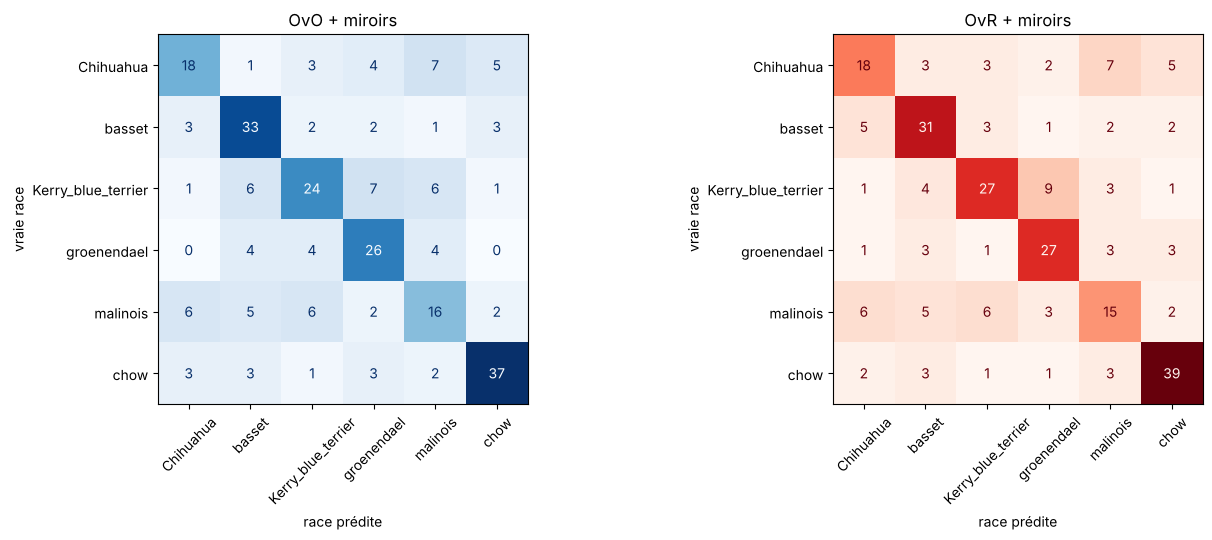

In [16]:
noms_races = [noms[k] for k in sorted(noms)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (nom, cmap) in zip(axes, [("OvO + miroirs", "Blues"), ("OvR + miroirs", "Reds")]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, resultats[nom][1]), display_labels=noms_races).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(nom); ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("race prédite"); ax.set_ylabel("vraie race")
plt.tight_layout()
plt.savefig("figures/matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

Le **chow**, rond et touffu, est le mieux reconnu ; le **malinois** est le plus difficile. Les confusions
viennent surtout de races proches en 64 × 64 : chihuahua et malinois (oreilles pointues dressées,
pelage fauve, et la PCA ne connaît pas la taille réelle de l'animal sur une image recadrée), ou Kerry
blue terrier et groenendael (deux chiens sombres au poil long). C'est la limite de caractéristiques
« faites à la main » sur des images en basse résolution.

## Bilan

- Recadrer et redimensionner sans déformer, puis combiner PCA par race et HOG, donne un SVM autour
  de 60 % sur 6 races proches, soit près de 4 fois mieux que le hasard.
- One-vs-Rest fait aussi bien que One-vs-One avec 2,5 fois moins de modèles.
- Le `Pipeline` et l'ordre « séparer, puis augmenter » sont indispensables pour un score honnête :
  sans eux, le score était gonflé de plusieurs points.